In [67]:
import pandas as pd

data=pd.read_csv("/content/sample_data/loan_data_set.csv")
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [68]:
# Importing the relavant libraries for modelling:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import minmax_scale
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix


In [69]:
#checking null values in loan id
data.Loan_ID.value_counts(dropna=False)

,count
Loan_ID,
LP002990,1
LP001002,1
LP001003,1
LP001005,1
LP001006,1
...,...
LP001024,1
LP001020,1
LP001018,1


In [70]:
#Checking null values in Gender
data.Gender.value_counts(dropna=False)
# print("Null values are: ",data.Gender.isnull().sum())

,count
Gender,
Male,489
Female,112
NaN,13


<Axes: xlabel='Gender', ylabel='count'>

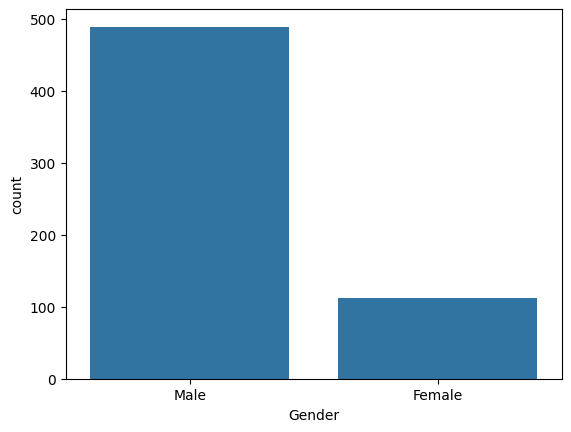

In [71]:
sns.countplot(x=data['Gender'])

In [72]:
# df=pd.DataFrame(data)
for col in data.columns:
  print(data[col].value_counts(dropna=False))
  print('\n\n')

Loan_ID
LP002990    1
LP001002    1
LP001003    1
LP001005    1
LP001006    1
           ..
LP001024    1
LP001020    1
LP001018    1
LP001014    1
LP001013    1
Name: count, Length: 614, dtype: int64



Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64



Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64



Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64



Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64



Self_Employed
No     500
Yes     82
NaN     32
Name: count, dtype: int64



ApplicantIncome
2500     9
4583     6
6000     6
2600     6
5000     5
        ..
11000    1
3416     1
1907     1
3125     1
3727     1
Name: count, Length: 505, dtype: int64



CoapplicantIncome
0.0       273
1666.0      5
2083.0      5
2500.0      5
1625.0      3
         ... 
2816.0      1
1083.0      1
3021.0      1
983.0       1
5063.0      1
Name: count, Length: 287, dtype: int64



LoanA

In [73]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


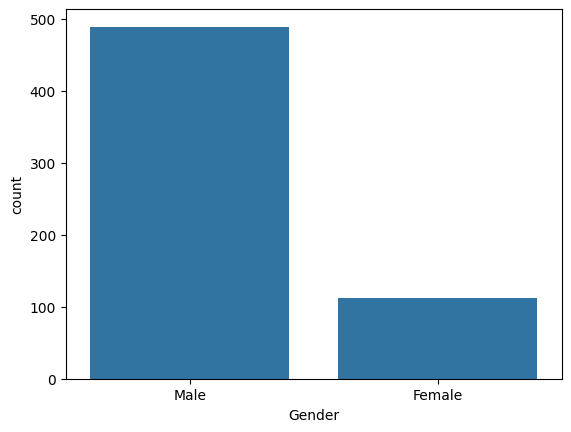

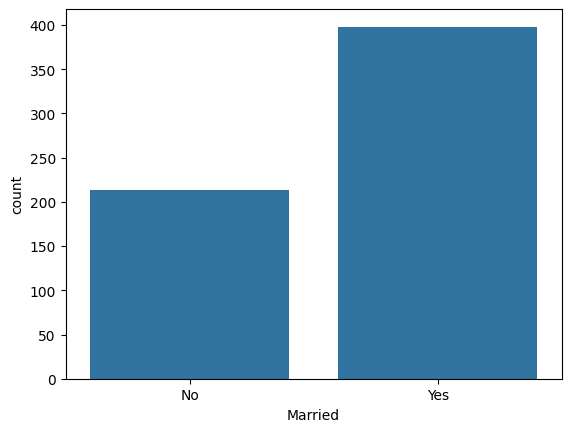

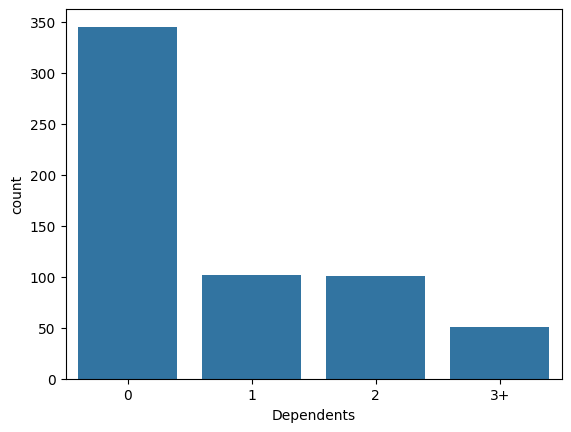

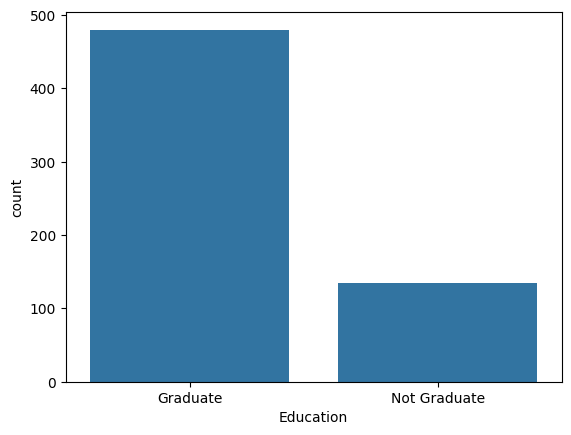

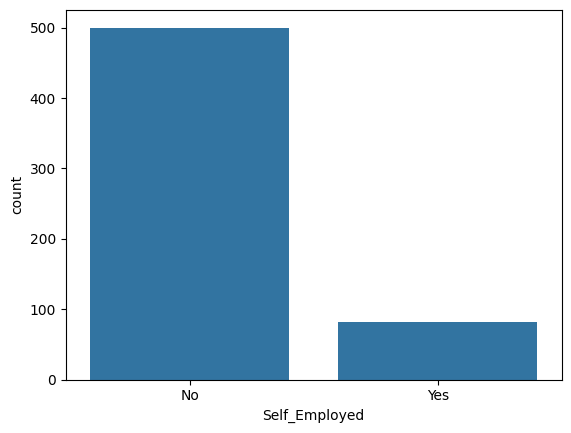

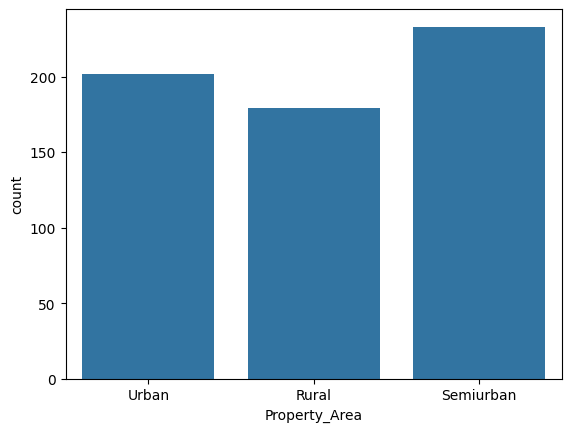

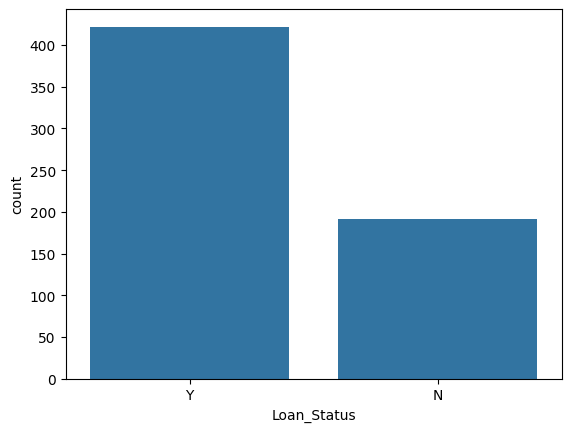

In [74]:
#Exploration of Category_cols
# category_col=data.select_dtypes(exclude='number').columns.drop('Loan_ID')
category_col=data.select_dtypes(include=['object', 'string', 'category']).columns.drop('Loan_ID')
# category_col=df.drop(columns=['Loan_ID'])  #its for dataframe and one more method is       Here is no need to convert into dataframe
# category_col.drop('Loan_ID', axis=1, inplace = True)  #it is also for dataframe
for col in category_col:
  sns.countplot(x=data[col])
  plt.show()
  print('\n\n')


<Axes: xlabel='Credit_History', ylabel='count'>

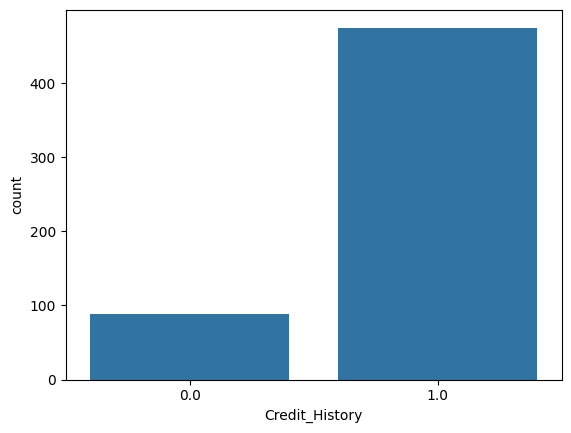

In [75]:
#Credit History
sns.countplot(x=data.Credit_History)

<Axes: xlabel='Loan_Amount_Term', ylabel='count'>

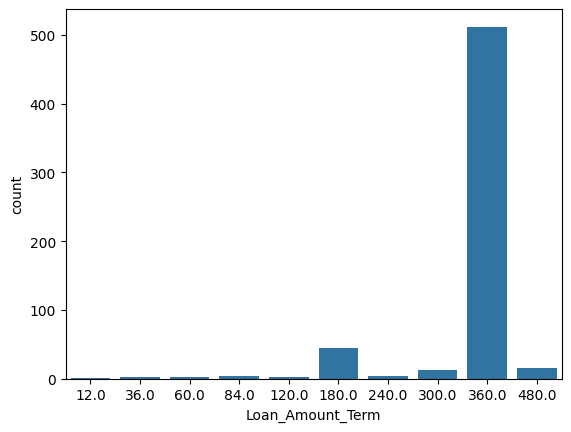

In [76]:
#Loan Amount Term
sns.countplot(x=data['Loan_Amount_Term'])

/tmp/ipython-input-930150952.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=data['Loan_Status'], palette='viridis')


<Axes: xlabel='Loan_Status', ylabel='count'>

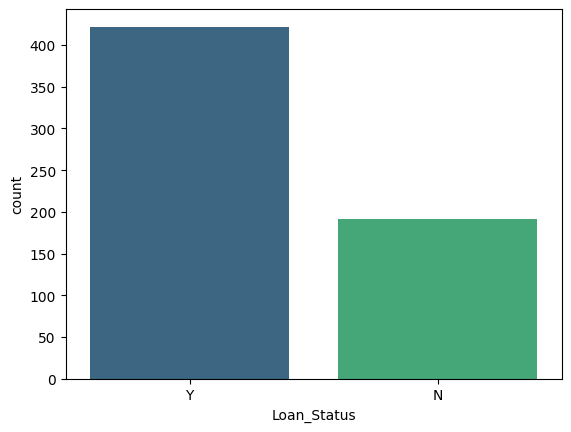

In [77]:
#Loan Status
# sns.countplot(x=data['Loan_Status'], hue=data['Gender'], palette='viridis')
sns.countplot(x=data['Loan_Status'], palette='viridis')

In [78]:
count_app=len(data[data.Loan_Status=='Y'])

count_not_app=len(data[data.Loan_Status=='N'])

count_null=len(data[data.Loan_Status.isnull()])

total_count=len(data.Loan_Status)

print("Percent of Loan Status approved = {:.1f}%".format((count_app/total_count)*100))
print("Percent of Loan Status not approved = {:.1f}%".format((count_not_app/total_count)*100))
print("Percent of Loan Status null values = {:.1f}%".format((count_null/total_count)*100))

'''Number of loans approved are higher than rejected and also there are no null values in the columns'''

Percent of Loan Status approved = 68.7%
Percent of Loan Status not approved = 31.3%
Percent of Loan Status null values = 0.0%


'Number of loans approved are higher than rejected and also there are no null values in the columns'

In [79]:
#Exploring Numerical Columns
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [80]:
numerical_features=['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
data[numerical_features].describe()

'''Std. deviation of applicant income and coapplicant income is so high so the data is very much spread
   mean should be greater than std.deviation then data is good or it depends on the data as well
   +-1 sigma cover 68% of data and +-2 sigma covers 95% of data and +-3 sigma covers 99.7% of data
   so when data is fall in this +-1 sigma then it is normally distributed or +-2 it is right or it depends'''

'Std. deviation of applicant income and coapplicant income is so high so the data is very much spread\n   mean should be greater than std.deviation then data is good or it depends on the data as well\n   +-1 sigma cover 68% of data and +-2 sigma covers 95% of data and +-3 sigma covers 99.7% of data\n   so when data is fall in this +-1 sigma then it is normally distributed or +-2 it is right or it depends'

'Insights: It is right skewed distribution because its tail is going in right'

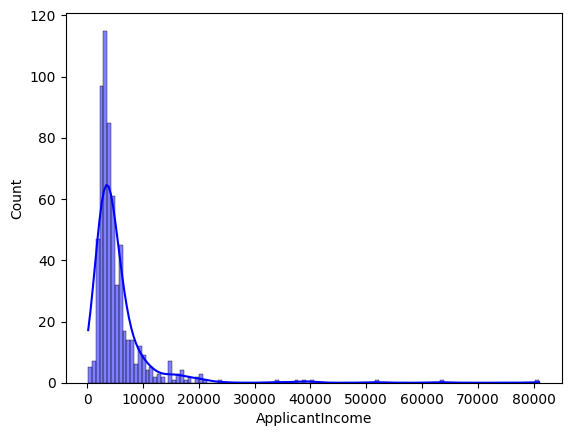

In [81]:
#Check the distribution of all numerical features
sns.histplot(data['ApplicantIncome'], kde=True, color='blue')

'''Insights: It is right skewed distribution because its tail is going in right'''

Standard Deviation should be low for better now see
A machine of making screw and mean diameter of screw is 1 cm and a table which is checking screw it takes of diameter 0.98cm to 1.02 cm means +-0.2 cm and then if std deviation going out of this range then think how screw are wasted if not understand then see first of ML Project time 2:20 and downloaded image 21 August 2025

Difference between Variance And Standard Deviation first these are two using for measure spread variance is also doing same work but it changes unit from km/l to km^2/l^2 and then we square root of variance which standard deviation

'Now see the std. deviation is less than mean then also it is little right skewed'

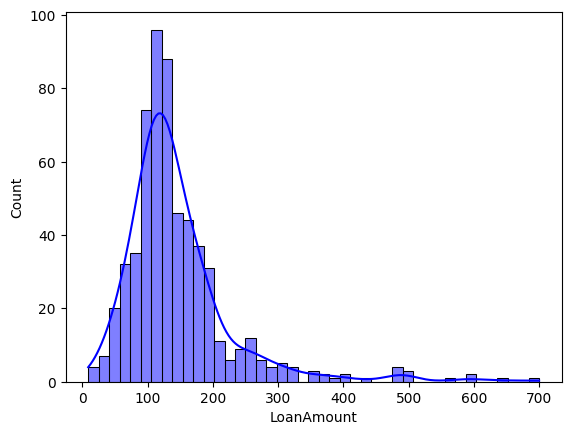

In [82]:
sns.histplot(data['LoanAmount'], kde=True, color='blue')

'''Now see the std. deviation is less than mean then also it is little right skewed'''

#Want to clear the concept of std. deviation then take data find mean and std deviation then make plot or graph then understand
#Hint is divide std. deviation by 2 then add and subtract from mean then make plot how it varying and what you need


<Axes: xlabel='LoanAmount', ylabel='Density'>

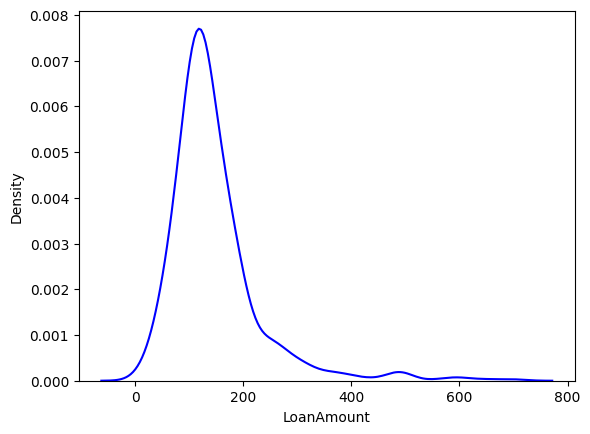

In [83]:
sns.kdeplot(data['LoanAmount'], color='b')

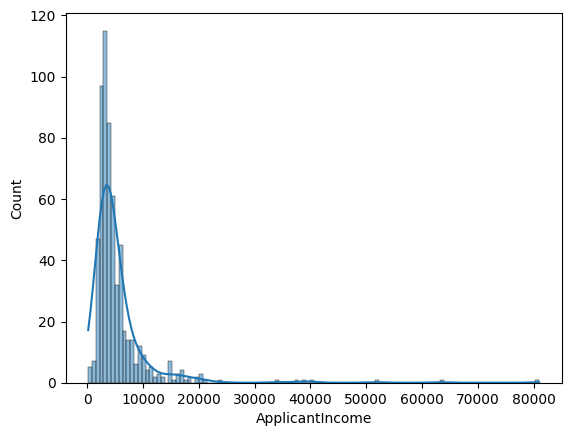

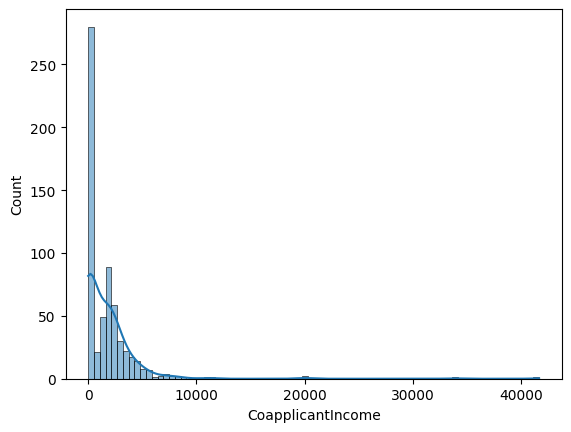

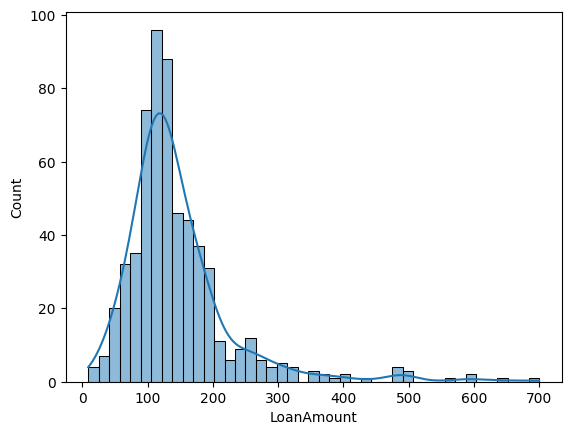

In [84]:
#Create the histogram for all numerical features together
#Using For loop
for col in numerical_features:
  sns.histplot(data[col], kde=True)
  plt.show()
  print('\n\n')


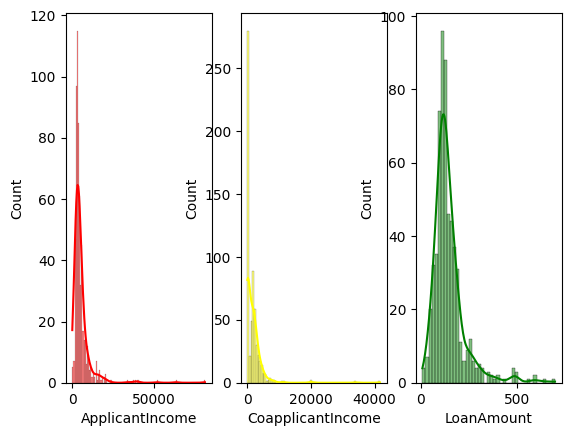

In [85]:
#Using subplot
plt.subplot(1,3,1)
sns.histplot(data['ApplicantIncome'], kde=True, color='red')

plt.subplot(1,3,2)
sns.histplot(data['CoapplicantIncome'], kde=True, color='yellow')

plt.subplot(1,3,3)
sns.histplot(data['LoanAmount'], kde=True, color='green')
plt.show()



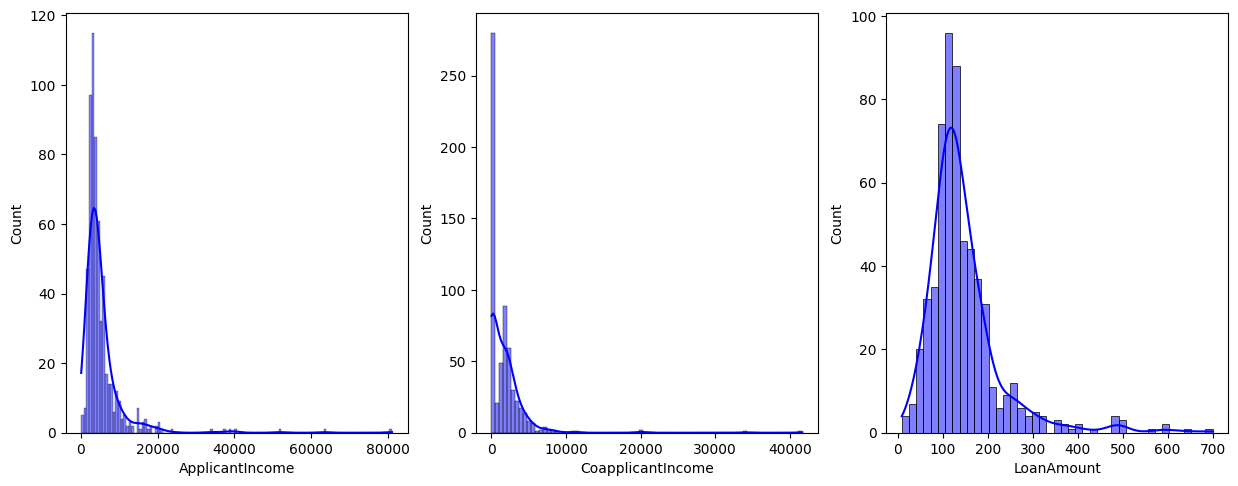

In [86]:
#For loop and Subplot both
plt.figure(figsize=(15,12))
for i in range(len(numerical_features)):
  plt.subplot(2,3,i+1)
  sns.histplot(data[numerical_features[i]], kde=True, color='b')

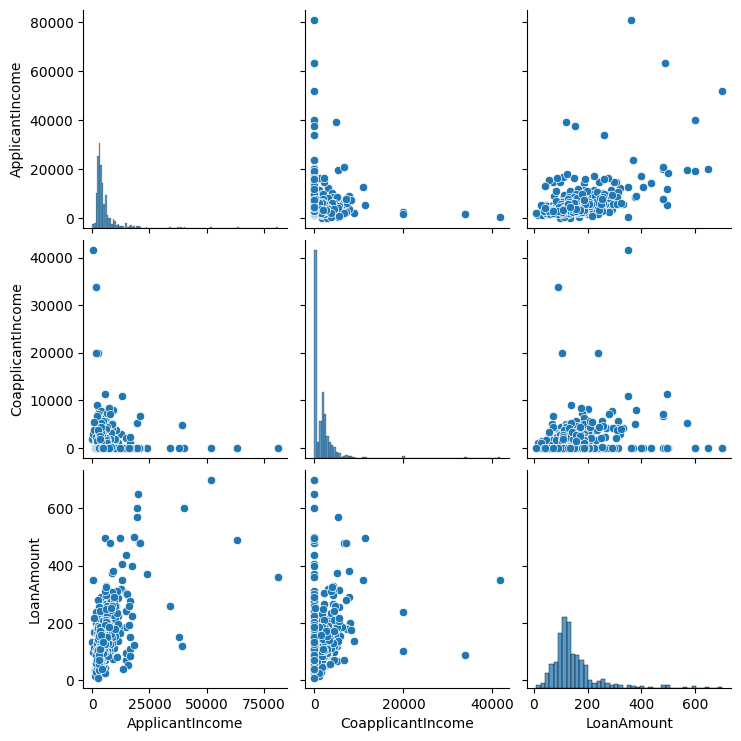

In [87]:
sns.pairplot(data[numerical_features])


In [88]:
'''EDA - Exploratory data analysis:

1. Univariate analysis : When we find the distribution of single independent variables


Creating a Violin plot/ Box plot


Threshold for outliers:
'''



'EDA - Exploratory data analysis:\n\n1. Univariate analysis : When we find the distribution of single independent variables\n\n\nCreating a Violin plot/ Box plot\n\n\nThreshold for outliers:\n'

<Axes: ylabel='ApplicantIncome'>

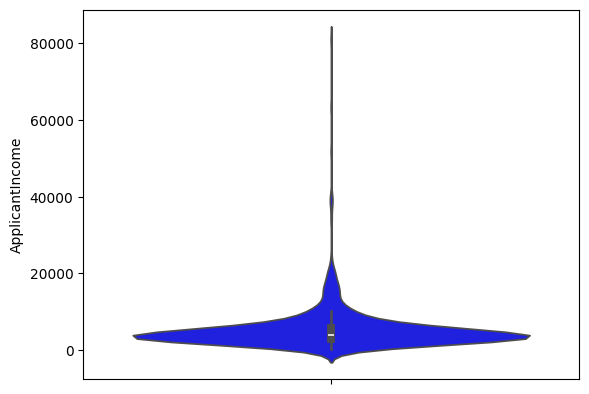

In [89]:
sns.violinplot(data['ApplicantIncome'], color='b')

<Axes: ylabel='CoapplicantIncome'>

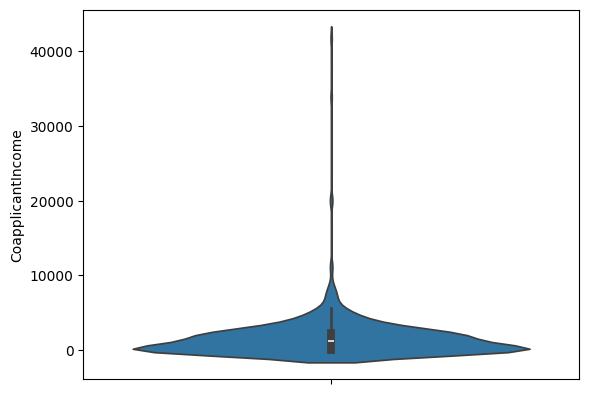

In [90]:
sns.violinplot(data['CoapplicantIncome'])

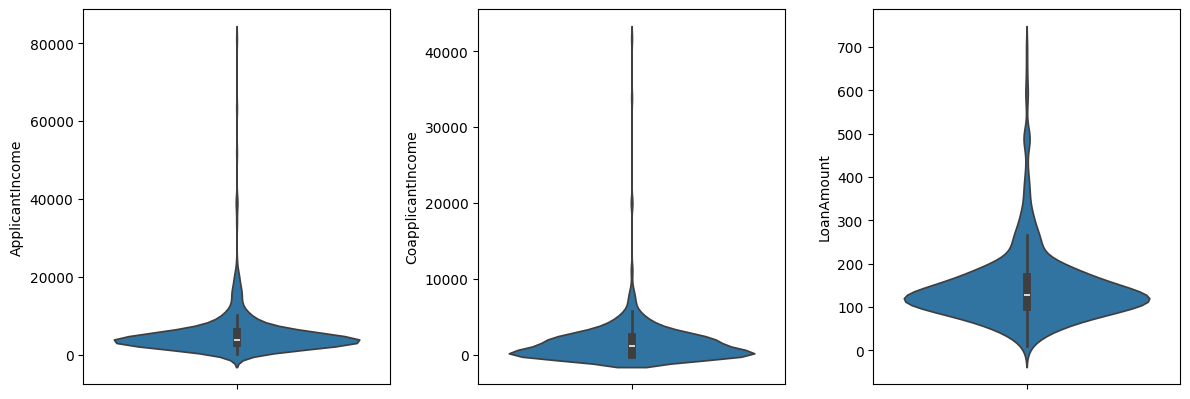

In [91]:
plt.figure(figsize=(12,8))
for i in range(len(numerical_features)):
  plt.subplot(2,3,i+1)
  sns.violinplot(data[numerical_features[i]])
  plt.tight_layout()


In [92]:
'''Bivariate Analysis
   Relationships between two variables
   a) Sometimes we check the relationship between target variable and independent variable
   b) We check the reltionship between two independent variable
   '''

'Bivariate Analysis\n   Relationships between two variables\n   a) Sometimes we check the relationship between target variable and independent variable\n   b) We check the reltionship between two independent variable\n   '

<Axes: xlabel='Gender'>

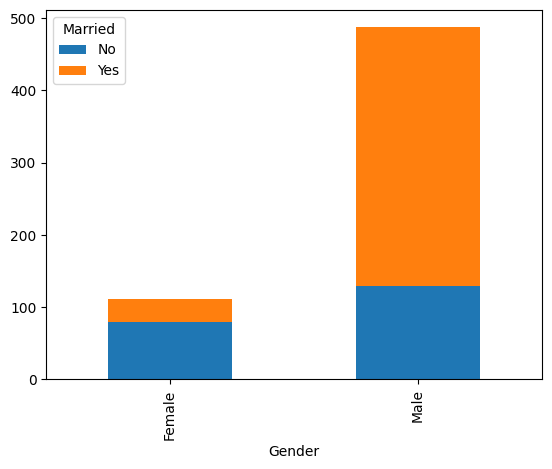

In [93]:
#Bi-variate
#Category variables

#Married and Gender
pd.crosstab(data.Gender, data.Married).plot(kind='bar', stacked=True)

<Axes: xlabel='Self_Employed'>

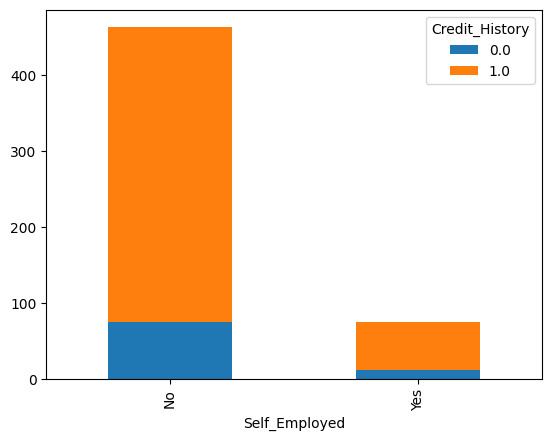

In [94]:
#Self Employed and Credit History
#Credit History = if 1 then good and he is taken loan elif 0 then bad and he never taken loan before
pd.crosstab(data.Self_Employed, data.Credit_History).plot(kind='bar', stacked=True)

<Axes: xlabel='Gender'>

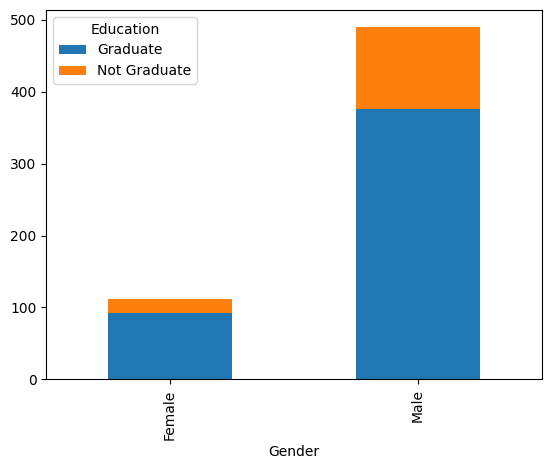

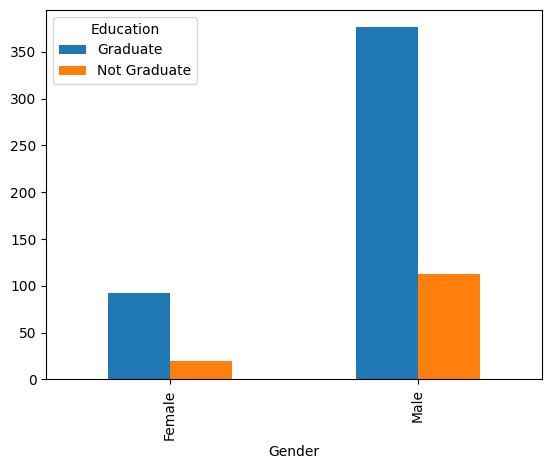

In [95]:
#Gender and Education
# plt.figure(figsize=(12,8))
# plt.subplot(1,2,1)
pd.crosstab(data.Gender, data.Education).plot(kind='bar', stacked=True)
# plt.subplot(1,2,2)

pd.crosstab(data.Gender, data.Education).plot(kind='bar')



In [96]:
'''EDA - Exploratory data analysis

   Insights from the charts
   Identifying outiers , distribution
'''

'EDA - Exploratory data analysis\n\n   Insights from the charts\n   Identifying outiers , distribution\n'

<Axes: xlabel='ApplicantIncome', ylabel='Loan_Status'>

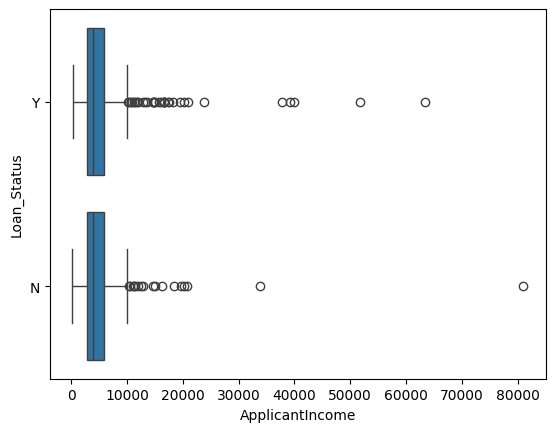

In [97]:
#relationship between categorical and numerical variables

#Loan status and applicant income

sns.boxplot(data, x=data['ApplicantIncome'], y=data['Loan_Status'])

<Axes: xlabel='ApplicantIncome', ylabel='Gender'>

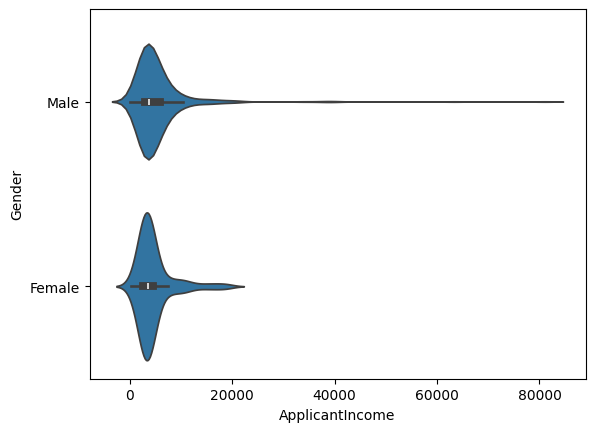

In [98]:
sns.violinplot(data, y=data.Gender, x=data.ApplicantIncome)

Pearson Correlation Coefficient:  0.5709090389885666


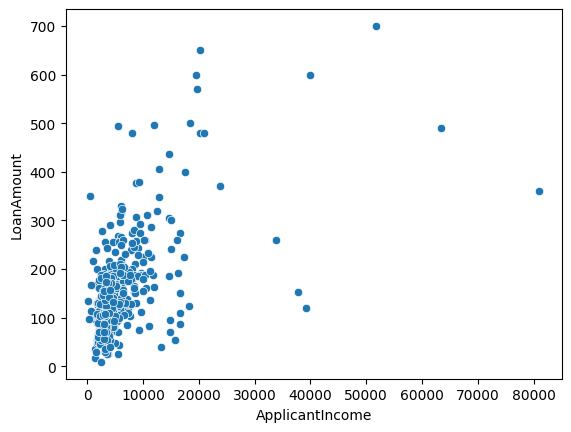

In [99]:
#Numerical to Numerical Relationship

#Applicant Income and Loan Status

sns.scatterplot(data, x=data.ApplicantIncome, y=data.LoanAmount)

print("Pearson Correlation Coefficient: ", data.ApplicantIncome.corr(data.LoanAmount))

<Axes: >

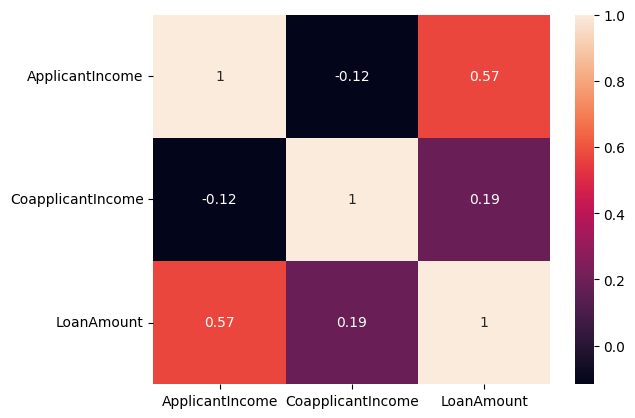

In [100]:
sns.heatmap(data[numerical_features].corr(), annot=True)

In [101]:
data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [102]:
#Pre processing
#Categorical Columns replace with mode
#Numerical Columns replace with mean and if outliers are more then replace with median
data.Gender=data.Gender.fillna(data.Gender.mode()[0])

data.Married=data.Married.fillna(data.Married.mode()[0])

data.Dependents=data.Dependents.fillna(data.Dependents.mode()[0])

data.Self_Employed=data.Self_Employed.fillna(data.Self_Employed.mode()[0])

data.LoanAmount=data.LoanAmount.fillna(data.LoanAmount.mean())

data.Loan_Amount_Term=data.Loan_Amount_Term.fillna(data.Loan_Amount_Term.mode()[0])

data.Credit_History=data.Credit_History.fillna(data.Credit_History.mode()[0])

In [103]:
data.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [104]:
#One Hot Coding
#when we transform our categorical columns into numerical columns, we call it one hot encoding

model_data = data.copy()

model_data = model_data.drop(['Loan_ID'], axis = 1) # Loan_ID was already dropped in a previous run
model_data



,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
609,Female,No,0,Graduate,No,2900,0.0,71.000000,360.0,1.0,Rural,Y
610,Male,Yes,3+,Graduate,No,4106,0.0,40.000000,180.0,1.0,Rural,Y
611,Male,Yes,1,Graduate,No,8072,240.0,253.000000,360.0,1.0,Urban,Y
612,Male,Yes,2,Graduate,No,7583,0.0,187.000000,360.0,1.0,Urban,Y


In [105]:
model_data=pd.get_dummies(model_data, dtype=int)
model_data

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Female,Gender_Male,Married_No,Married_Yes,Dependents_0,...,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban,Loan_Status_N,Loan_Status_Y
0,5849,0.0,146.412162,360.0,1.0,0,1,1,0,1,...,0,1,0,1,0,0,0,1,0,1
1,4583,1508.0,128.000000,360.0,1.0,0,1,0,1,0,...,0,1,0,1,0,1,0,0,1,0
2,3000,0.0,66.000000,360.0,1.0,0,1,0,1,1,...,0,1,0,0,1,0,0,1,0,1
3,2583,2358.0,120.000000,360.0,1.0,0,1,0,1,1,...,0,0,1,1,0,0,0,1,0,1
4,6000,0.0,141.000000,360.0,1.0,0,1,1,0,1,...,0,1,0,1,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,2900,0.0,71.000000,360.0,1.0,1,0,1,0,1,...,0,1,0,1,0,1,0,0,0,1
610,4106,0.0,40.000000,180.0,1.0,0,1,0,1,0,...,1,1,0,1,0,1,0,0,0,1
611,8072,240.0,253.000000,360.0,1.0,0,1,0,1,0,...,0,1,0,1,0,0,0,1,0,1
612,7583,0.0,187.000000,360.0,1.0,0,1,0,1,0,...,0,1,0,1,0,0,0,1,0,1


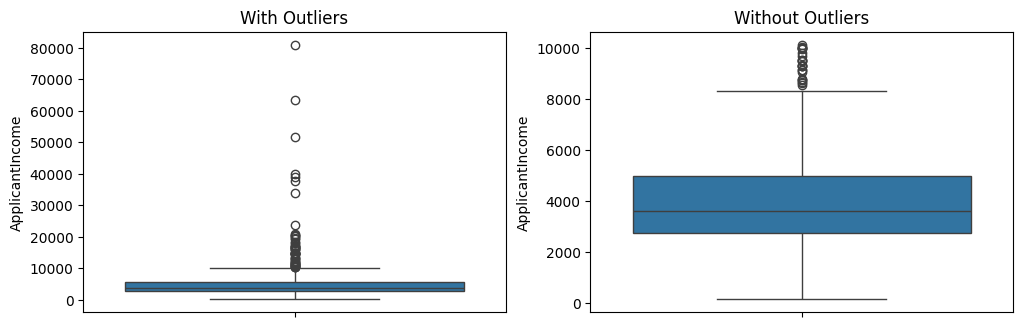

In [106]:
#Remove Outliers
Q1=model_data.ApplicantIncome.quantile(0.25)
Q3=model_data.ApplicantIncome.quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

outliers = model_data[(model_data.ApplicantIncome < lower_bound) | (model_data.ApplicantIncome > upper_bound)]
# display(outliers)
# outliers.value_counts().sum()

# Filter out the outliers to get the data without outliers
not_outliers = model_data[(model_data.ApplicantIncome >= lower_bound) & (model_data.ApplicantIncome <= upper_bound)]

plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
sns.boxplot(data.ApplicantIncome)
plt.title("With Outliers")
plt.subplot(2,2,2)
plt.title("Without Outliers")
sns.boxplot(not_outliers['ApplicantIncome'])
plt.show()

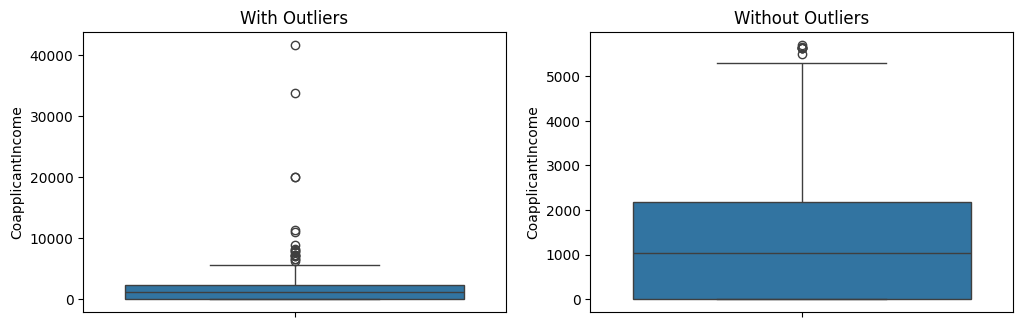

In [107]:
#Remove outliers in coapplicant income
Q1=model_data.CoapplicantIncome.quantile(0.25)
Q3=model_data.CoapplicantIncome.quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

outliers=model_data[(model_data.CoapplicantIncome<(Q1-1.5*IQR))|(model_data.CoapplicantIncome>(upper_bound))]

not_outliers=model_data[(model_data.CoapplicantIncome>=(lower_bound))&(model_data.CoapplicantIncome<=(upper_bound))]

plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
sns.boxplot(model_data.CoapplicantIncome)
plt.title("With Outliers")
plt.subplot(2,2,2)
plt.title("Without Outliers")
sns.boxplot(not_outliers['CoapplicantIncome'])
plt.show()

<Axes: xlabel='ApplicantIncome', ylabel='Count'>

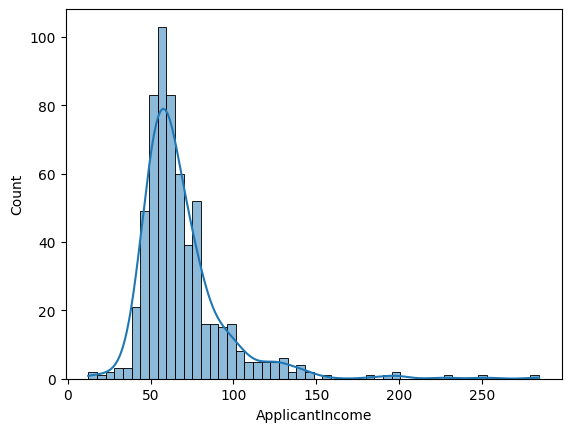

In [108]:
#Square root Trnasformation
import numpy as np
model_data.ApplicantIncome=np.sqrt(model_data.ApplicantIncome)

sns.histplot(model_data.ApplicantIncome, kde=True)

<Axes: xlabel='ApplicantIncome', ylabel='Count'>

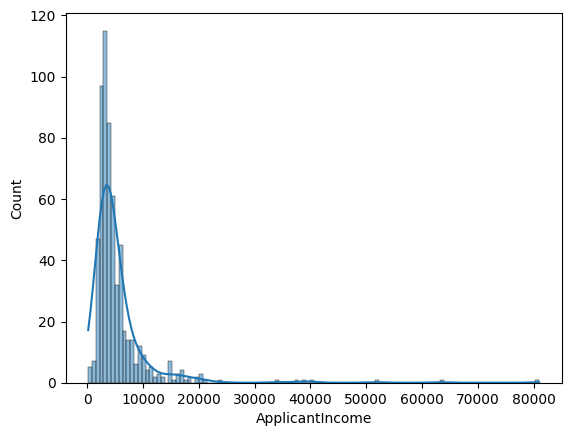

In [109]:
sns.histplot(data.ApplicantIncome, kde=True)

In [110]:
#Tranformation = It is remove to skewness and try to make it normal distribution look like it shrinks the data
#There are two type of transformation
#Sqrt Transformation for short values sqrt of 100 is 10 , sqrt of 10000 is 100 difference is 90
#Log for high values and log 100=2, log 10000=4 difference is 2 only

<Axes: xlabel='CoapplicantIncome', ylabel='Count'>

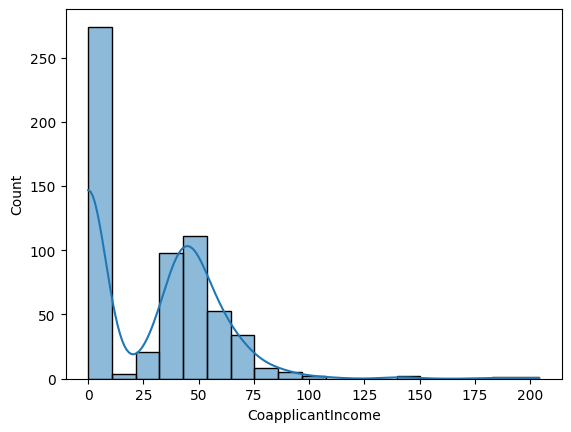

In [111]:
#Square root Trnasformation of Coapplicant Income
import numpy as np
model_data.CoapplicantIncome=np.sqrt(model_data.CoapplicantIncome)

sns.histplot(model_data.CoapplicantIncome, kde=True)

<Axes: xlabel='CoapplicantIncome', ylabel='Count'>

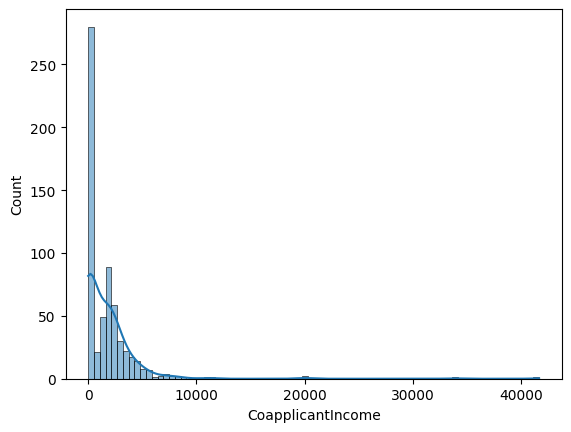

In [112]:
sns.histplot(data.CoapplicantIncome, kde=True)

<Axes: xlabel='LoanAmount', ylabel='Count'>

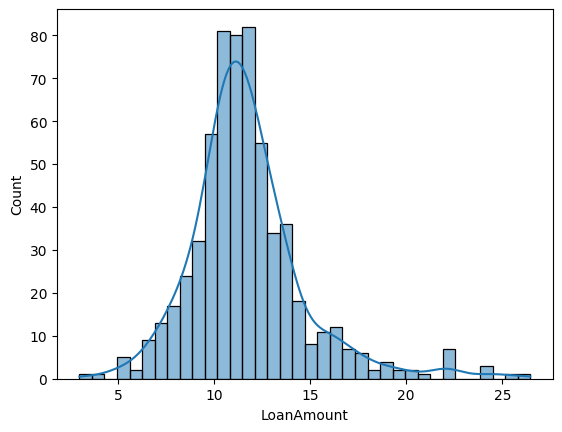

In [113]:
#Square root Trnasformation of Loan Amount
import numpy as np
model_data.LoanAmount=np.sqrt(model_data.LoanAmount)

sns.histplot(model_data.LoanAmount, kde=True)

<Axes: xlabel='LoanAmount', ylabel='Count'>

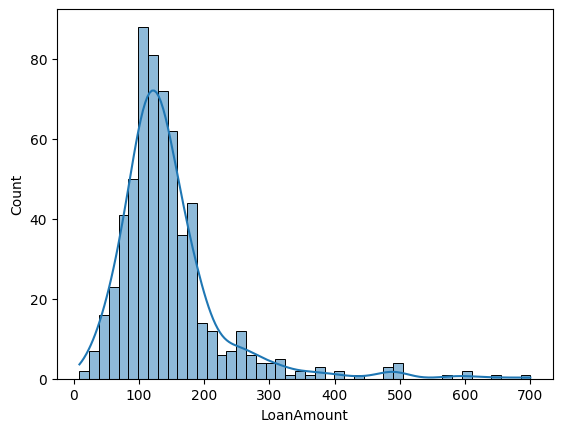

In [114]:
sns.histplot(data.LoanAmount, kde=True)

In [115]:
#Imabalanced dataset in loan_statues
#Smote Synthetic Minimily Over Sampling Technique
#Identify the minority class= N Oversampling
#Finding Nearest NEighbours KNN
#Generates Synthetic samples
#Loan status yes of 400 and no of 100 so it is more influencing by yes 400 so we use snot to generate synthetic data


In [116]:
model_data.drop(['Loan_Status_N'],axis = 1, inplace = True)
model_data.rename(columns={'Loan_Status_Y':'Loan_Status'}, inplace=True)
model_data

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Female,Gender_Male,Married_No,Married_Yes,Dependents_0,...,Dependents_2,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban,Loan_Status
0,76.478755,0.000000,12.100089,360.0,1.0,0,1,1,0,1,...,0,0,1,0,1,0,0,0,1,1
1,67.697858,38.832976,11.313708,360.0,1.0,0,1,0,1,0,...,0,0,1,0,1,0,1,0,0,0
2,54.772256,0.000000,8.124038,360.0,1.0,0,1,0,1,1,...,0,0,1,0,0,1,0,0,1,1
3,50.823223,48.559242,10.954451,360.0,1.0,0,1,0,1,1,...,0,0,0,1,1,0,0,0,1,1
4,77.459667,0.000000,11.874342,360.0,1.0,0,1,1,0,1,...,0,0,1,0,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,53.851648,0.000000,8.426150,360.0,1.0,1,0,1,0,1,...,0,0,1,0,1,0,1,0,0,1
610,64.078077,0.000000,6.324555,180.0,1.0,0,1,0,1,0,...,0,1,1,0,1,0,1,0,0,1
611,89.844310,15.491933,15.905974,360.0,1.0,0,1,0,1,0,...,0,0,1,0,1,0,0,0,1,1
612,87.080423,0.000000,13.674794,360.0,1.0,0,1,0,1,0,...,1,0,1,0,1,0,0,0,1,1


In [117]:
x=model_data.drop(['Loan_Status'], axis=1) #It is training data so we take all data columns except loan status
y=model_data['Loan_Status']  #it is assigning to y because it is test data it is to be predict

In [118]:
x,y=SMOTE().fit_resample(x,y)

<Axes: xlabel='count', ylabel='Loan_Status'>

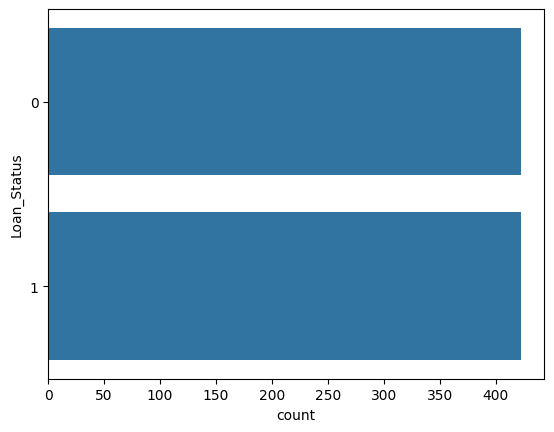

In [119]:
sns.countplot(data=model_data, y=y)
# sns.countplot(data=data, y=y)

In [120]:
x

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Female,Gender_Male,Married_No,Married_Yes,Dependents_0,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,76.478755,0.000000,12.100089,360.0,1.000000,0,1,1,0,1,0,0,0,1,0,1,0,0,0,1
1,67.697858,38.832976,11.313708,360.0,1.000000,0,1,0,1,0,1,0,0,1,0,1,0,1,0,0
2,54.772256,0.000000,8.124038,360.0,1.000000,0,1,0,1,1,0,0,0,1,0,0,1,0,0,1
3,50.823223,48.559242,10.954451,360.0,1.000000,0,1,0,1,1,0,0,0,0,1,1,0,0,0,1
4,77.459667,0.000000,11.874342,360.0,1.000000,0,1,1,0,1,0,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
839,65.401415,0.000000,10.775539,360.0,0.719511,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0
840,67.757309,87.256611,16.056458,360.0,0.730713,0,1,0,1,0,0,0,0,1,0,1,0,0,0,0
841,50.557732,42.643760,11.441135,180.0,0.674692,0,1,0,1,0,1,0,0,0,1,1,0,0,0,0
842,47.987247,56.450610,10.840554,360.0,0.410627,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0


In [121]:
x= MinMaxScaler().fit_transform(x) #Minmaxscaler fix range and takes all data in a certain range like salary goes 10 to 10000 and loan amount goes 10 to 10,00,000 so laon amount impact the data so we take this all data in range 0 to 1
x #You can see this output

array([[0.23583451, 0.        , 0.38793922, ..., 0.        , 0.        ,
        1.        ],
       [0.20359418, 0.19024119, 0.3544156 , ..., 1.        , 0.        ,
        0.        ],
       [0.15613596, 0.        , 0.21843912, ..., 0.        , 0.        ,
        1.        ],
       ...,
       [0.14066173, 0.20891007, 0.35984783, ..., 0.        , 0.        ,
        0.        ],
       [0.13122383, 0.27654927, 0.33424491, ..., 0.        , 0.        ,
        0.        ],
       [0.14862805, 0.20612223, 0.41465676, ..., 0.        , 0.        ,
        0.        ]])

In [122]:
x

array([[0.23583451, 0.        , 0.38793922, ..., 0.        , 0.        ,
        1.        ],
       [0.20359418, 0.19024119, 0.3544156 , ..., 1.        , 0.        ,
        0.        ],
       [0.15613596, 0.        , 0.21843912, ..., 0.        , 0.        ,
        1.        ],
       ...,
       [0.14066173, 0.20891007, 0.35984783, ..., 0.        , 0.        ,
        0.        ],
       [0.13122383, 0.27654927, 0.33424491, ..., 0.        , 0.        ,
        0.        ],
       [0.14862805, 0.20612223, 0.41465676, ..., 0.        , 0.        ,
        0.        ]])

In [123]:
#Splitting the data into train and test
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2, random_state=42)

In [124]:
'''Modelling

    1. training
    2. testing

    Logistic regression - Classification alogorithm
    '''

'Modelling\n\n    1. training\n    2. testing\n\n    Logistic regression - Classification alogorithm\n    '

In [125]:
classifier=LogisticRegression(solver='saga', max_iter=500, random_state=1)  #saga is optimization algorithm

classifier.fit(x_train, y_train)

y_pred=classifier.predict(x_test)

print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.74      0.84        94
           1       0.75      0.97      0.85        75

    accuracy                           0.85       169
   macro avg       0.86      0.86      0.85       169
weighted avg       0.87      0.85      0.85       169

[[70 24]
 [ 2 73]]


In [126]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Create a KNN classifier instance
knn_classifier = KNeighborsClassifier(n_neighbors=5) # You can adjust the number of neighbors (k)

# Train the model
knn_classifier.fit(x_train, y_train)

# Make predictions on the test set
y_pred_knn = knn_classifier.predict(x_test)

# Evaluate the model
print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))
print("\nKNN Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))


KNN Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.71      0.79        94
           1       0.71      0.89      0.79        75

    accuracy                           0.79       169
   macro avg       0.80      0.80      0.79       169
weighted avg       0.81      0.79      0.79       169


KNN Confusion Matrix:
[[67 27]
 [ 8 67]]


Our KNN's model has the highest accuracy of:81.07%


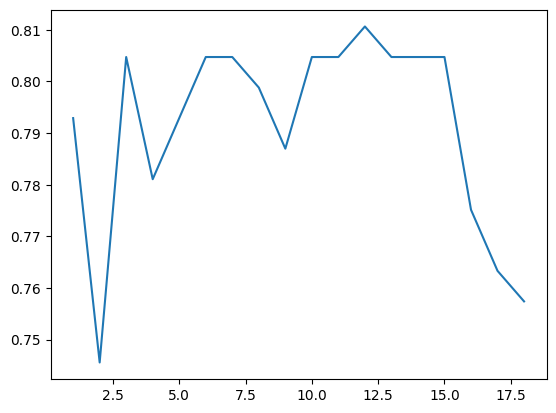

In [127]:

#KNN K nearest neighbor

#try to find the value of k
score = []

for i in range(1,19):
  KNclassifier = KNeighborsClassifier(n_neighbors= i)
  KNclassifier.fit(x_train,y_train)
  score.append(KNclassifier.score(x_test,y_test))

plt.plot(range(1,19),score)

max_acc = max(score)

print("Our KNN's model has the highest accuracy of:{:.2f}%".format(max_acc*100))



In [128]:
#SVM/ Naive Bayes? Gaussian Naive stats Decision Tree, Bagging ALgo(Random Forest)

In [129]:
from sklearn.svm import SVC

# Create an SVM classifier instance
# You can experiment with different kernels like 'linear', 'poly', 'rbf'
svm_classifier = SVC(kernel='linear', random_state=42)

# Train the model
svm_classifier.fit(x_train, y_train)

# Make predictions on the test set
y_pred_svm = svm_classifier.predict(x_test)

# Evaluate the model
print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))
print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.74      0.84        94
           1       0.75      0.97      0.85        75

    accuracy                           0.85       169
   macro avg       0.86      0.86      0.85       169
weighted avg       0.87      0.85      0.85       169


SVM Confusion Matrix:
[[70 24]
 [ 2 73]]


In [130]:
# X = model_data.drop(['Loan_Status_N', 'Loan_Status_Y'], axis=1)
# y = model_data['Loan_Status_Y']

In [131]:
# from imblearn.over_sampling import SMOTE

# smote = SMOTE(random_state=42)
# X_resampled, y_resampled = smote.fit_resample(X, y)

In [132]:
# y_resampled.value_counts()